# 03 · Linear and probabilistic classification models

**CSE274 Unit III.** Supervised learning; the perceptron and logistic regression; the Naive Bayes classifier; k-nearest neighbours, decision trees and support vector machines; and how to evaluate a classifier: the confusion matrix, accuracy, precision, recall, F1, ROC and precision–recall curves.

Every model is trained on the same 40,000 training fields and scored on the same 20,000 held-out fields, with the pre-processing pipeline from notebooks 01–02.

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from irrigate import data, evaluate, plotting, preprocess
plotting.setup()

df = data.sample(60_000, seed=3)
y = df[data.TARGET].cat.codes.to_numpy()
train, test, y_tr, y_te = train_test_split(df, y, test_size=1 / 3, stratify=y, random_state=0)
print(len(train), "training fields ·", len(test), "test fields")
results = {}

def fit_and_score(name, pipe, train_df=train, y_train=y_tr):
    t0 = time.perf_counter()
    pipe.fit(train_df, y_train)
    seconds = time.perf_counter() - t0
    pred = pipe.predict(test)
    proba = pipe.predict_proba(test) if hasattr(pipe, "predict_proba") else None
    results[name] = {**evaluate.scores(y_te, pred, proba), "train seconds": seconds}
    return pipe, pred, proba

40000 training fields · 20000 test fields


## 1. Supervised learning
Learn a mapping from features *x* to a known label *y* from labelled examples, then predict *y* for new *x*. Classification predicts a category (here Low / Medium / High); regression predicts a number (notebook 04). Every model below is a different answer to "what shape can the boundary between classes take?"

## 2. Linear classification models

### 2.1 The perceptron
The oldest learning algorithm (Rosenblatt, 1958): a weighted sum and a step function, *ŷ = sign(w·x + b)*. It updates the weights only on mistakes, *w ← w + η y x*, and is guaranteed to converge only if the classes are linearly separable. Written out for the binary "needs water" problem, then compared with scikit-learn's version:

In [2]:
from sklearn.linear_model import Perceptron

cols = preprocess.column_transformer(engineered=True)
feat = preprocess.pipeline(Perceptron(), engineered=True).steps[0][1]
Xtr = cols.fit_transform(feat.fit(train).transform(train))
Xte = cols.transform(feat.transform(test))
b_tr, b_te = np.where(y_tr > 0, 1, -1), np.where(y_te > 0, 1, -1)

w, b = np.zeros(Xtr.shape[1]), 0.0
mistakes = []
for epoch in range(15):
    errors = 0
    for i in np.random.default_rng(epoch).permutation(len(Xtr)):
        if b_tr[i] * (Xtr[i] @ w + b) <= 0:
            w += b_tr[i] * Xtr[i]
            b += b_tr[i]
            errors += 1
    mistakes.append(errors)
print("mistakes per epoch:", mistakes)
print(f"from-scratch perceptron test accuracy: {np.mean(np.sign(Xte @ w + b) == b_te):.4f}")
print(f"sklearn Perceptron test accuracy:      {np.mean(Perceptron(random_state=0).fit(Xtr, b_tr).predict(Xte) == b_te):.4f}")

mistakes per epoch: [5411, 5406, 5380, 5346, 5408, 5279, 5289, 5396, 5330, 5381, 5346, 5359, 5347, 5283, 5418]
from-scratch perceptron test accuracy: 0.8844
sklearn Perceptron test accuracy:      0.8617


The mistakes never reach zero: the classes are not linearly separable, so the perceptron keeps bouncing. Logistic regression fixes that by learning probabilities instead of hard decisions.

### 2.2 Logistic regression
Models P(class | x) with the sigmoid (binary) or softmax (multi-class) of a linear score, trained by minimising cross-entropy (CSE273 notebook 05 trained exactly this model with hand-written optimisers). Its coefficients are readable: positive pushes towards a class.

In [3]:
from sklearn.linear_model import LogisticRegression

logit, pred_lr, proba_lr = fit_and_score("Logistic regression", preprocess.pipeline(LogisticRegression(max_iter=3000), engineered=True))
names = logit.named_steps["columns"].get_feature_names_out()
coef = pd.DataFrame(logit.named_steps["model"].coef_.T, index=names, columns=data.CLASSES)
coef.reindex(coef["High"].abs().sort_values(ascending=False).index).head(10).round(3)

,Low,Medium,High
Soil_Moisture,2.038,1.089,-3.127
thirsty_stage,-2.409,0.339,2.070
Mulching_Used_Yes,1.124,0.441,-1.565
Temperature_C,-1.155,-0.215,1.371
Water_Source_Groundwater,0.497,0.380,-0.878
Season_Kharif,0.453,0.383,-0.836
Mulching_Used_No,0.235,0.565,-0.801
no_mulch,-0.895,0.119,0.776
Season_Zaid,0.454,0.317,-0.771
Season_Rabi,0.452,0.307,-0.759


## 3. Probabilistic classification models

### 3.1 The Naive Bayes classifier
Applies Bayes' theorem with the "naive" assumption that features are independent given the class: P(y | x) ∝ P(y) Π P(xⱼ | y). Gaussian NB models each numeric feature as a normal distribution per class. It's fast and needs little data, and the assumption suits this dataset unusually well, since its features really are nearly independent.

In [4]:
from sklearn.naive_bayes import GaussianNB

nb, pred_nb, proba_nb = fit_and_score("Gaussian Naive Bayes", preprocess.pipeline(GaussianNB(), engineered=True))
gnb = nb.named_steps["model"]
pd.DataFrame(gnb.theta_, columns=nb.named_steps["columns"].get_feature_names_out(), index=data.CLASSES)[["Soil_Moisture", "Temperature_C", "Wind_Speed_kmh", "dryness"]].round(2)

,Soil_Moisture,Temperature_C,Wind_Speed_kmh,dryness
Low,0.36,-0.18,-0.21,-0.39
Medium,-0.46,0.21,0.25,0.46
High,-1.21,0.89,0.75,1.74


Above: the per-class means (on the standardised scale) the model learned. High fields are about one standard deviation drier, hotter and windier.

## 4. Nonlinear and distance-based models

### 4.1 k-nearest neighbours
Predicts the majority class of the *k* closest training points. No training at all, all the work at prediction time; *k* trades variance (small k) against bias (large k).

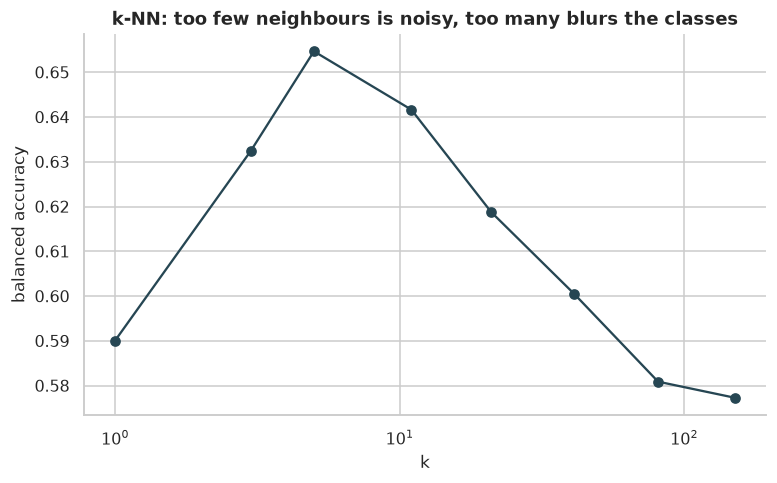

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score

ks = [1, 3, 5, 11, 21, 41, 81, 151]
small_tr = train.iloc[:15000]
knn_curve = []
for k in ks:
    pipe = preprocess.pipeline(KNeighborsClassifier(k, weights="distance", n_jobs=-1)).fit(small_tr, y_tr[:15000])
    knn_curve.append(balanced_accuracy_score(y_te[:5000], pipe.predict(test.iloc[:5000])))
fig, ax = plt.subplots()
ax.plot(ks, knn_curve, "o-", color=plotting.ACCENT)
ax.set(xscale="log", xlabel="k", ylabel="balanced accuracy", title="k-NN: too few neighbours is noisy, too many blurs the classes")
plotting.save("i03-knn")
plt.show()
best_k = ks[int(np.argmax(knn_curve))]
knn, pred_knn, proba_knn = fit_and_score(f"k-NN (k = {best_k})", preprocess.pipeline(KNeighborsClassifier(best_k, weights="distance", n_jobs=-1)))

### 4.2 Decision tree
Splits the data with yes/no questions, each chosen to make the child nodes as pure as possible (Gini impurity). The result can be read as rules, and its axis-aligned splits match the threshold effects in this data.

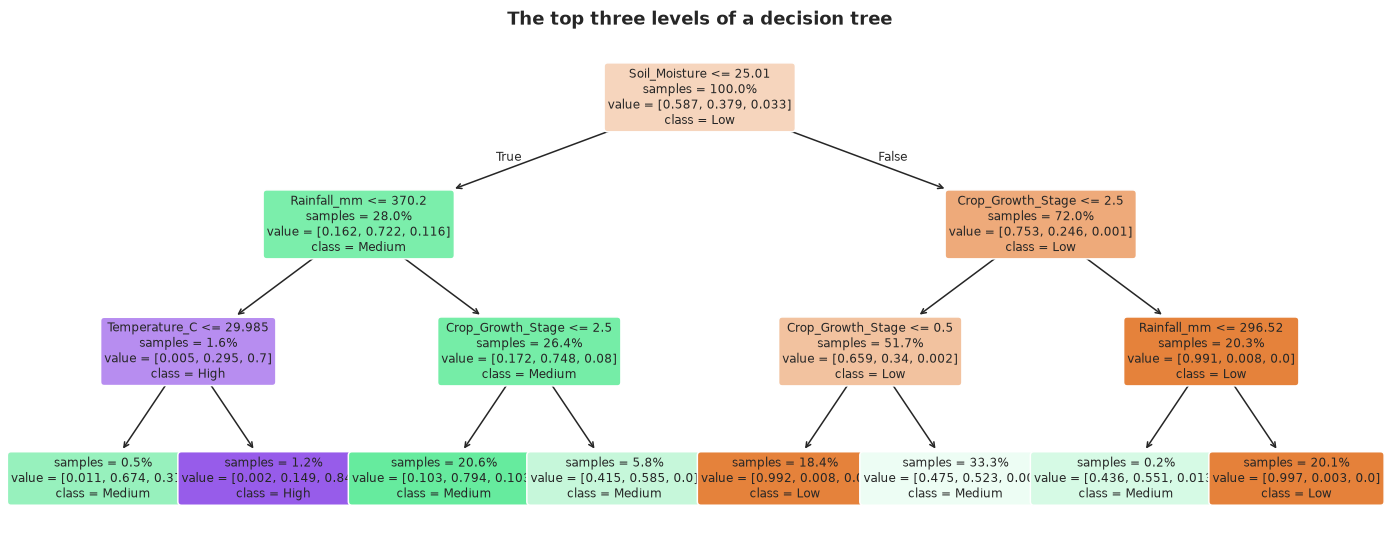

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree, pred_tree, proba_tree = fit_and_score("Decision tree (depth 10)", preprocess.pipeline(DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=0), scale=None))
small_tree = preprocess.pipeline(DecisionTreeClassifier(max_depth=3, random_state=0), scale=None).fit(train, y_tr)
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(small_tree.named_steps["model"], feature_names=small_tree.named_steps["columns"].get_feature_names_out(), class_names=data.CLASSES,
          filled=True, rounded=True, fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("The top three levels of a decision tree", fontweight="bold")
plotting.save("i03-tree")
plt.show()

The first questions are exactly the EDA findings: is the soil dry (moisture ≤ 25%)? If so, is it one of the driest fields (rain ≤ 370 mm) and is it hot (above 30 °C)? If not, is the crop in a thirsty growth stage? The High leaf (85% High) is dry, very low rain and hot.

### 4.3 Support vector machine (SVM)
Finds the boundary with the widest **margin** between classes; only the points on or inside the margin (the support vectors) define it. The kernel trick lets it draw curved boundaries: an RBF kernel compares points by similarity in an implicit infinite-dimensional space. SVM training grows roughly with the square of the data size, so it is trained on 12,000 fields.

In [7]:
from sklearn.svm import SVC, LinearSVC

svm_tr, svm_y = train.iloc[:12000], y_tr[:12000]
for name, model in [("Linear SVM", LinearSVC(C=1.0, max_iter=5000)), ("RBF SVM", SVC(C=3.0, gamma="scale", probability=True, random_state=0))]:
    pipe, *_ = fit_and_score(name, preprocess.pipeline(model, engineered=True), svm_tr, svm_y)
rbf = pipe.named_steps["model"]
print("support vectors per class:", dict(zip(data.CLASSES, rbf.n_support_)), "of", len(svm_tr), "training fields")

/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


support vectors per class: {'Low': np.int32(1383), 'Medium': np.int32(1661), 'High': np.int32(251)} of 12000 training fields


## 5. Model evaluation metrics

### 5.1 The confusion matrix
Rows are the true class, columns the prediction. Every other metric is a summary of this table.

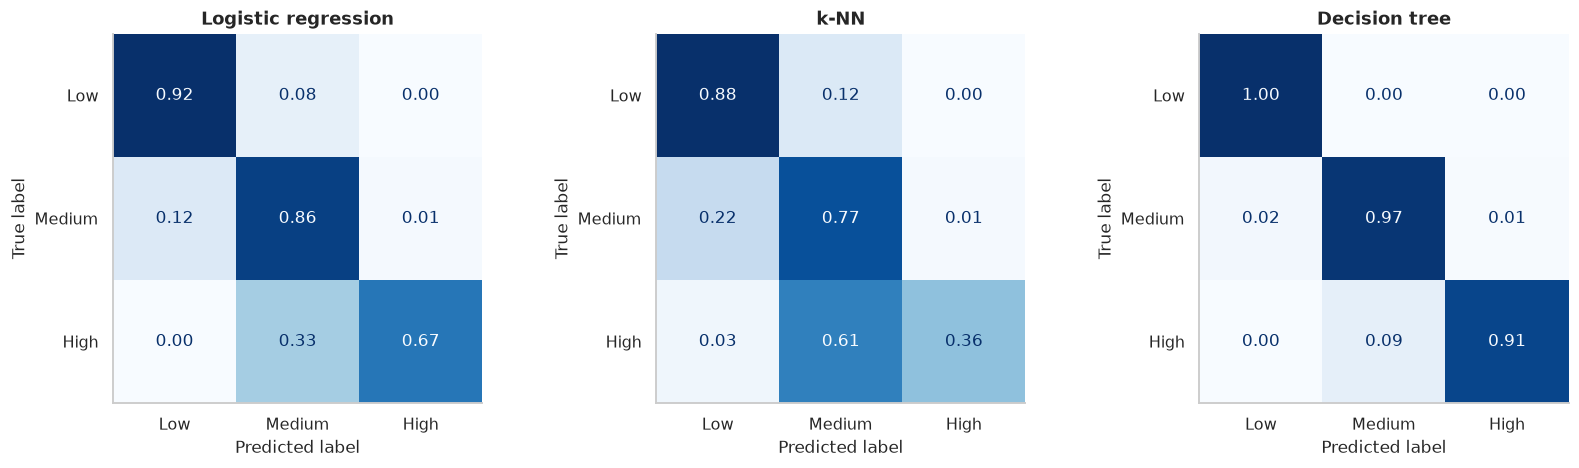

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (name, pred) in zip(axes, [("Logistic regression", pred_lr), ("k-NN", pred_knn), ("Decision tree", pred_tree)]):
    evaluate.confusion(y_te, pred, ax=ax, title=name)
fig.tight_layout()
plotting.save("i03-confusion")
plt.show()

### 5.2 Basic metrics
- **Accuracy** = correct / all. Misleading with imbalance.
- **Precision** = TP / (TP + FP): of the fields flagged High, how many really are.
- **Recall** = TP / (TP + FN): of the truly High fields, how many were caught.
- **F1** = harmonic mean of precision and recall.
- **Balanced accuracy** = mean recall over classes: the competition metric.

In [9]:
evaluate.per_class(y_te, pred_tree).round(3)

,precision,recall,F1,support
Low,0.985,0.996,0.991,11743
Medium,0.986,0.971,0.978,7590
High,0.935,0.912,0.923,667


For irrigation, a missed High field (a crop under water stress) costs more than an unnecessary check, so High **recall** is the number to watch.

### 5.3 Advanced evaluation: ROC and PR curves
Both sweep the decision threshold instead of fixing it. The ROC curve plots true-positive rate against false-positive rate; its area (AUC) is the chance a random positive is ranked above a random negative. With a rare class, ROC can look great while precision is poor, so the **precision–recall** curve is the more honest view for High (dotted lines: the no-skill baseline = class frequency).

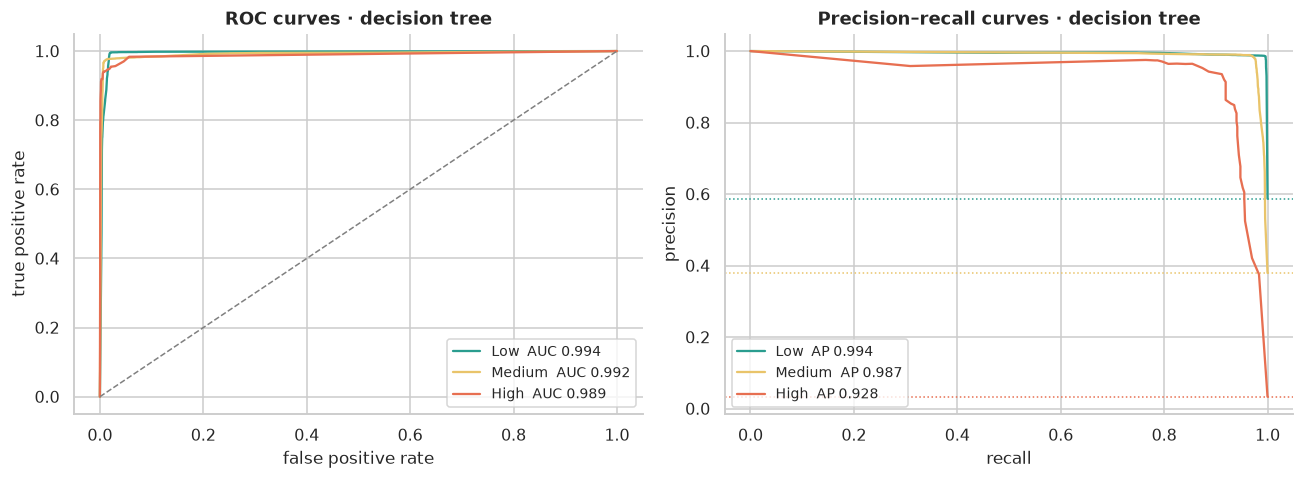

In [10]:
evaluate.roc_pr(y_te, proba_tree, name="· decision tree")
plt.tight_layout()
plotting.save("i03-roc-pr")
plt.show()

### Every model side by side

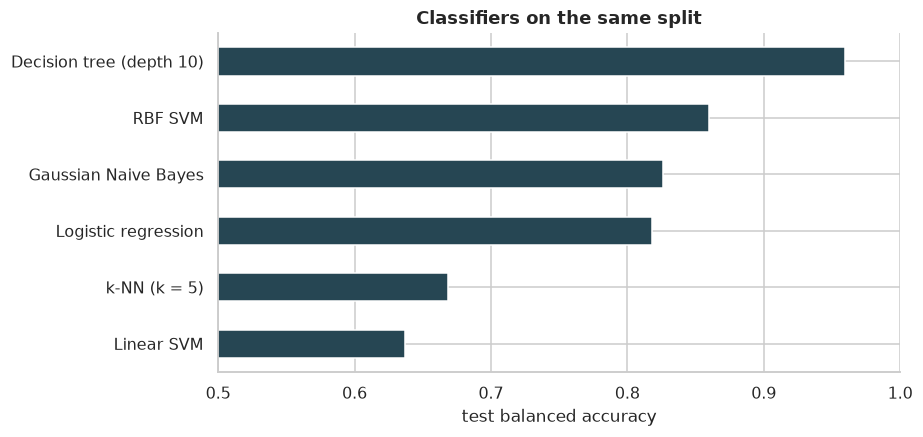

,balanced accuracy,accuracy,macro F1,High recall,High precision,"ROC AUC (macro, OvR)",train seconds
Decision tree (depth 10),0.9595,0.9838,0.9641,0.9115,0.9354,0.9917,0.6663
RBF SVM,0.8600,0.9283,0.8738,0.7181,0.8160,0.9851,19.3763
Gaussian Naive Bayes,0.8259,0.8446,0.7938,0.8201,0.6202,0.9526,0.1537
Logistic regression,0.8179,0.8900,0.8361,0.6717,0.8043,0.9729,0.9607
k-NN (k = 5),0.6686,0.8182,0.7022,0.3613,0.6925,0.8976,0.0814
Linear SVM,0.6370,0.8729,0.6605,0.1289,0.9773,NaN,0.1783


In [11]:
board = pd.DataFrame(results).T.sort_values("balanced accuracy", ascending=False)
ax = board["balanced accuracy"].iloc[::-1].plot.barh(color=plotting.ACCENT, figsize=(8, 4))
ax.set(xlabel="test balanced accuracy", xlim=(0.5, 1), title="Classifiers on the same split")
plotting.save("i03-board")
plt.show()
board.round(4)

The tree does best: its axis-aligned splits fit the thresholds in the data, and it is fast. The ensembles in notebook 05 combine hundreds of such trees.

| Syllabus topic | Where |
|---|---|
| Introduction to supervised learning | 1 |
| Perceptron (from scratch and scikit-learn), logistic regression | 2.1, 2.2 |
| Naive Bayes | 3.1 |
| k-NN, decision tree, SVM (linear and RBF) | 4.1–4.3 |
| Confusion matrix, accuracy / precision / recall / F1 | 5.1, 5.2 |
| ROC and PR curves | 5.3 |